<a href="https://colab.research.google.com/github/team2601/arabic-handwriting-cnn/blob/main/Notebooks/2_Baseline_and_Paper_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 3: Baseline MLP & Original Paper CNN on AHAWP (18 Classes)



## 1. Setup, Reproducibility & Mount Google Drive

In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

# Fix random seeds for reproducibility
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/DL_Project/data/ahawp_18classes_32x32"
RESULTS_DIR = "/content/drive/MyDrive/DL_Project/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load Preprocessed AHAWP Splits (60% Train / 20% Val / 20% Test) && inverse images!!!!


In [ ]:
# Load the shared splits created by AHAWP_Preprocessing_Clean.ipynb
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_val   = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val   = np.load(os.path.join(DATA_DIR, "y_val.npy"))
X_test  = np.load(os.path.join(DATA_DIR, "X_test.npy"))
y_test  = np.load(os.path.join(DATA_DIR, "y_test.npy"))

with open(os.path.join(DATA_DIR, "label_map.json"), "r", encoding="utf-8") as f:
    label_map = json.load(f)

class_names = label_map["classes"]
NUM_CLASSES = label_map["num_classes"]
INPUT_SHAPE = X_train.shape[1:]  # (32, 32, 1)

def invert_and_enhance(X_arr, bg_cutoff=0.05):
    """Invert white background to 0.0 and stretch each image's ink stroke peak to 1.0."""
    X_inv = 1.0 - X_arr.astype(np.float32)
    X_inv = np.clip(X_inv - bg_cutoff, 0.0, 1.0)
    peak = X_inv.max(axis=(1, 2, 3), keepdims=True)
    safe_peak = np.where(peak > 1e-5, peak, 1.0)
    return (X_inv / safe_peak).astype(np.float32)

# Apply to all three splits independently (zero data leakage)
X_train = invert_and_enhance(X_train)
X_val   = invert_and_enhance(X_val)
X_test  = invert_and_enhance(X_test)

# Sanity checks
assert not np.isnan(X_train).any(), "Found NaN in X_train!"
blank_train = int((X_train.max(axis=(1, 2, 3)) == 0).sum())
print(f"Blank images in train: {blank_train}")
print(f"After invert + enhance -> mean: {X_train.mean():.4f} | std: {X_train.std():.4f}")

# (Optional) Save the inverted splits once so the whole team can load them directly
INV_DIR = "/content/drive/MyDrive/DL_Project/data/ahawp_18classes_32x32_inv"
os.makedirs(INV_DIR, exist_ok=True)
for name, arr in [
    ("X_train.npy", X_train), ("y_train.npy", y_train),
    ("X_val.npy", X_val),     ("y_val.npy", y_val),
    ("X_test.npy", X_test),   ("y_test.npy", y_test),
]:
    np.save(os.path.join(INV_DIR, name), arr)
with open(os.path.join(INV_DIR, "label_map.json"), "w", encoding="utf-8") as f:
    json.dump(label_map, f, indent=2)

# One-hot encode labels for categorical cross-entropy
y_train_cat = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_cat   = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_cat  = keras.utils.to_categorical(y_test, NUM_CLASSES)

print(f"Classes ({NUM_CLASSES}): {class_names}")
print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Blank images in train: 2
After invert + enhance -> mean: 0.0400 | std: 0.1529
Classes (18): ['ain', 'alif', 'beh', 'dal', 'feh', 'heh', 'jeem', 'kaf', 'lam', 'meem', 'noon', 'qaf', 'raa', 'sad', 'seen', 'tah', 'waw', 'yaa']
Train: (31427, 32, 32, 1) | Val: (10476, 32, 32, 1) | Test: (10476, 32, 32, 1)


## 3. Shared Hyperparameters & Evaluation Helpers



In [ ]:
# Shared training settings (matching Paper Sections 5.4 & 6.1)
EPOCHS = 30
BATCH_SIZE = 64       # Paper did not report batch size; 64 is standard and fast on T4 GPU
LEARNING_RATE = 0.001

def plot_learning_curves(history, model_name, save_path):
    """Plot and save training & validation accuracy and loss curves."""
    epochs_range = range(1, len(history.history["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs_range, history.history["accuracy"], label="Train Accuracy")
    axes[0].plot(epochs_range, history.history["val_accuracy"], label="Val Accuracy")
    axes[0].set_title(f"{model_name} — Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs_range, history.history["loss"], label="Train Loss")
    axes[1].plot(epochs_range, history.history["val_loss"], label="Val Loss")
    axes[1].set_title(f"{model_name} — Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Categorical Cross-Entropy Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved learning curve to:", save_path)


def evaluate_on_test(model, model_name, short_tag):
    """Evaluate model once on the test set and save metrics + confusion matrix."""
    train_loss, train_acc = model.evaluate(X_train, y_train_cat, batch_size=BATCH_SIZE, verbose=0)
    val_loss, val_acc     = model.evaluate(X_val, y_val_cat, batch_size=BATCH_SIZE, verbose=0)
    test_loss, test_acc   = model.evaluate(X_test, y_test_cat, batch_size=BATCH_SIZE, verbose=0)

    y_pred_probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(
        y_test, y_pred, average="weighted", zero_division=0
    )
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0
    )

    print(f"================ {model_name} ================")
    print(f"Train Accuracy:     {train_acc * 100:.2f}%")
    print(f"Val Accuracy:       {val_acc * 100:.2f}%")
    print(f"Test Accuracy:      {test_acc * 100:.2f}%")
    print(f"Weighted Precision: {prec_w * 100:.2f}%")
    print(f"Weighted Recall:    {rec_w * 100:.2f}%")
    print(f"Weighted F1-Score:  {f1_w * 100:.2f}%")
    print(f"Macro Avg (P/R/F1): {prec_m * 100:.2f}% / {rec_m * 100:.2f}% / {f1_m * 100:.2f}%\n")

    # Per-class precision, recall, F1 (required by guidelines & paper Table 3)
    print("Per-Class Classification Report:")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4, zero_division=0))

    report_dict = classification_report(
        y_test, y_pred, target_names=class_names, output_dict=True, zero_division=0
    )
    pd.DataFrame(report_dict).T.to_csv(os.path.join(RESULTS_DIR, f"{short_tag}_per_class_report.csv"))

    # Confusion matrix with counts annotated inside cells
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(cm, cmap="Blues")
    fig.colorbar(im, ax=ax)

    ticks = np.arange(NUM_CLASSES)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=9)
    ax.set_yticklabels(class_names, fontsize=9)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_title(f"{model_name} — Test Confusion Matrix")

    thresh = cm.max() / 2.0
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > thresh else "black",
            )

    cm_path = os.path.join(RESULTS_DIR, f"{short_tag}_confusion_matrix.png")
    plt.tight_layout()
    plt.savefig(cm_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved confusion matrix to:", cm_path)

    summary = {
        "Model": model_name,
        "Dataset": "AHAWP (18 classes)",
        "Train Acc (%)": round(train_acc * 100, 2),
        "Val Acc (%)": round(val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Precision (%)": round(prec_w * 100, 2),
        "Recall (%)": round(rec_w * 100, 2),
        "F1-Score (%)": round(f1_w * 100, 2),
        "Macro F1 (%)": round(f1_m * 100, 2),
    }
    return summary, y_pred, cm

## 4. Model 1 — Simple Baseline (MLP)



In [ ]:
set_seed(SEED)

baseline_mlp = keras.Sequential([
    keras.Input(shape=INPUT_SHAPE),
    keras.layers.Flatten(),                      # 32x32x1 -> 1024
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="Baseline_MLP")

baseline_mlp.summary()

Model: "Baseline_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 297,618 (1.14 MB)

 Trainable params: 297,618 (1.14 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.3656 - loss: 2.0359 - val_accuracy: 0.5446 - val_loss: 1.5082
Epoch 2/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5419 - loss: 1.4735 - val_accuracy: 0.6121 - val_loss: 1.2585
Epoch 3/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6068 - loss: 1.2641 - val_accuracy: 0.6474 - val_loss: 1.1334
Epoch 4/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6431 - loss: 1.1294 - val_accuracy: 0.6671 - val_loss: 1.0599
Epoch 5/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6750 - loss: 1.0250 - val_accuracy: 0.6799 - val_loss: 1.0081
Epoch 6/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6917 - loss: 0.9583 - val_accuracy: 0.6899 - val_loss: 0.9848
Epoch 7/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7114 - loss: 0.8876 - val_accuracy: 0.6979 - val_loss: 0.9559
Epoch 8/15
492/492 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7296 - loss: 0.8309 - val_accuracy: 0

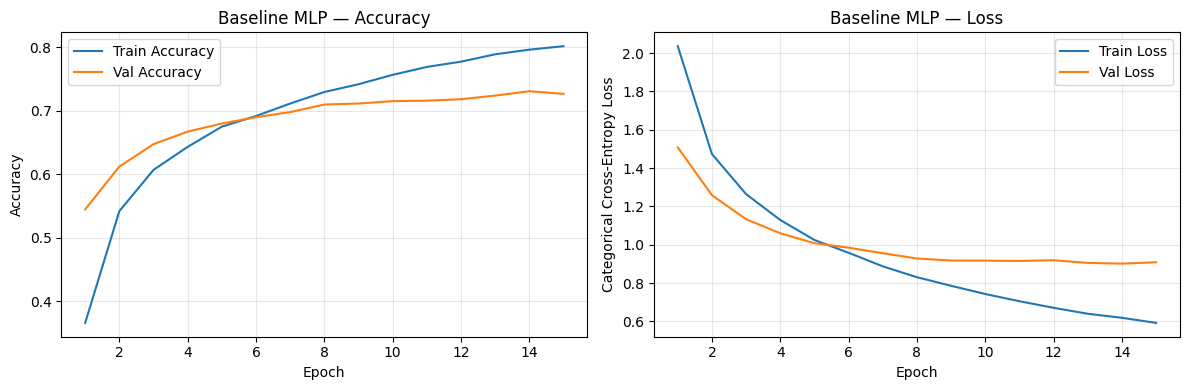

Saved learning curve to: /content/drive/MyDrive/DL_Project/results/baseline_mlp_curves.png


In [ ]:
baseline_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

mlp_history = baseline_mlp.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=15,
    batch_size=BATCH_SIZE,
    verbose=1,
)

baseline_mlp.save_weights(os.path.join(RESULTS_DIR, "baseline_mlp.weights.h5"))
plot_learning_curves(
    mlp_history,
    "Baseline MLP",
    os.path.join(RESULTS_DIR, "baseline_mlp_curves.png"),
)

## 5. Model 2 — Original Paper CNN

In [ ]:
set_seed(SEED)

paper_cnn = keras.Sequential([
    keras.Input(shape=INPUT_SHAPE),

    # Block 1: 32x32x1 -> 32x32x64 -> 16x16x64
    keras.layers.Conv2D(64, kernel_size=3, strides=1, padding="same", activation="relu"),
    keras.layers.MaxPooling2D(pool_size=2),
    keras.layers.Lambda(tf.nn.local_response_normalization, output_shape=lambda s: s),

    # Block 2: 16x16x64 -> 16x16x128 -> 8x8x128
    keras.layers.Conv2D(128, kernel_size=3, strides=1, padding="same", activation="relu"),
    keras.layers.MaxPooling2D(pool_size=2),
    keras.layers.Lambda(tf.nn.local_response_normalization, output_shape=lambda s: s),

    # Block 3: 8x8x128 -> 8x8x256 -> 4x4x256
    keras.layers.Conv2D(256, kernel_size=3, strides=1, padding="same", activation="relu"),
    keras.layers.MaxPooling2D(pool_size=2),
    keras.layers.Lambda(tf.nn.local_response_normalization, output_shape=lambda s: s),

    # Fully Connected Layers: 4096 -> 1024 -> 512 -> 18 (80% dropout on all FC layers)
    keras.layers.Flatten(),
    keras.layers.Dropout(0.8),
    keras.layers.Dense(1024, activation="relu"),
    keras.layers.Dropout(0.8),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dropout(0.8),
    keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="Original_Paper_CNN")

paper_cnn.summary()

Model: "Original_Paper_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_3 (Lambda)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_4 (Lambda)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_5 (Lambda)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 18)             │         9,234 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,099,026 (19.45 MB)

 Trainable params: 5,099,026 (19.45 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.1728 - loss: 2.5611 - val_accuracy: 0.4260 - val_loss: 1.8404
Epoch 2/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.4511 - loss: 1.6773 - val_accuracy: 0.7061 - val_loss: 0.9738
Epoch 3/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6034 - loss: 1.1899 - val_accuracy: 0.7937 - val_loss: 0.6582
Epoch 4/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6849 - loss: 0.9615 - val_accuracy: 0.8509 - val_loss: 0.5109
Epoch 5/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7259 - loss: 0.8375 - val_accuracy: 0.8662 - val_loss: 0.4648
Epoch 6/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7583 - loss: 0.7544 - val_accuracy: 0.8879 - val_loss: 0.4077
Epoch 7/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7794 - loss: 0.6913 - val_accuracy: 0.8943 - val_loss: 0.3724
Epoch 8/30
492/492 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7972 - loss: 0.6509 - val_acc

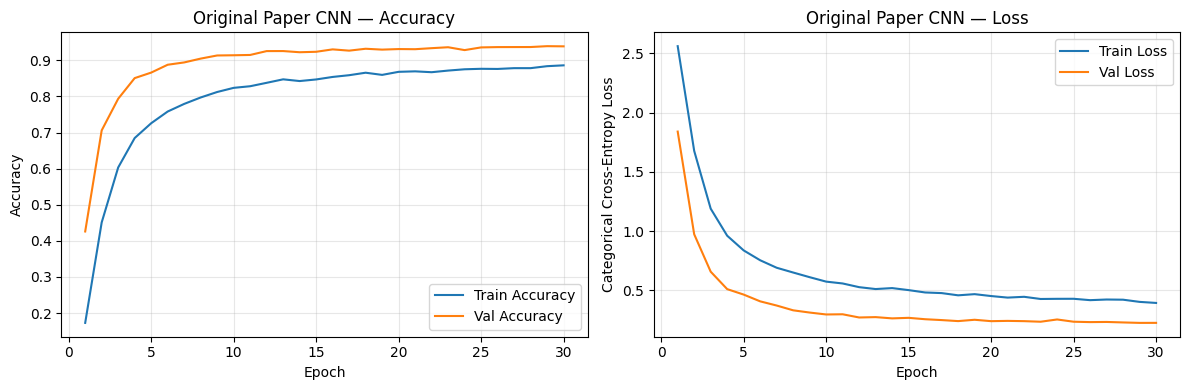

Saved learning curve to: /content/drive/MyDrive/DL_Project/results/paper_cnn_curves.png


In [ ]:
paper_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

cnn_history = paper_cnn.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
)

paper_cnn.save_weights(os.path.join(RESULTS_DIR, "paper_cnn_original.weights.h5"))
plot_learning_curves(
    cnn_history,
    "Original Paper CNN",
    os.path.join(RESULTS_DIR, "paper_cnn_curves.png"),
)

## 6. Final Test Set Evaluation Once



================ Baseline MLP ================
Train Accuracy:     91.77%
Val Accuracy:       72.66%
Test Accuracy:      73.08%
Weighted Precision: 73.28%
Weighted Recall:    73.08%
Weighted F1-Score:  73.00%
Macro Avg (P/R/F1): 73.51% / 73.46% / 73.32%

Per-Class Classification Report:
              precision    recall  f1-score   support

         ain     0.6796    0.7210    0.6997       656
        alif     0.8848    0.9370    0.9102       492
         beh     0.6493    0.7226    0.6840       656
         dal     0.6526    0.6128    0.6321       328
         feh     0.6632    0.6815    0.6722       650
         heh     0.7425    0.7607    0.7515       652
        jeem     0.7608    0.7271    0.7436       656
         kaf     0.7678    0.7409    0.7541       656
         lam     0.7215    0.8963    0.7995       656
        meem     0.7074    0.6966    0.7020       656
        noon     0.6618    0.7046    0.6826       650
         qaf     0.7559    0.6365    0.6911       652
         

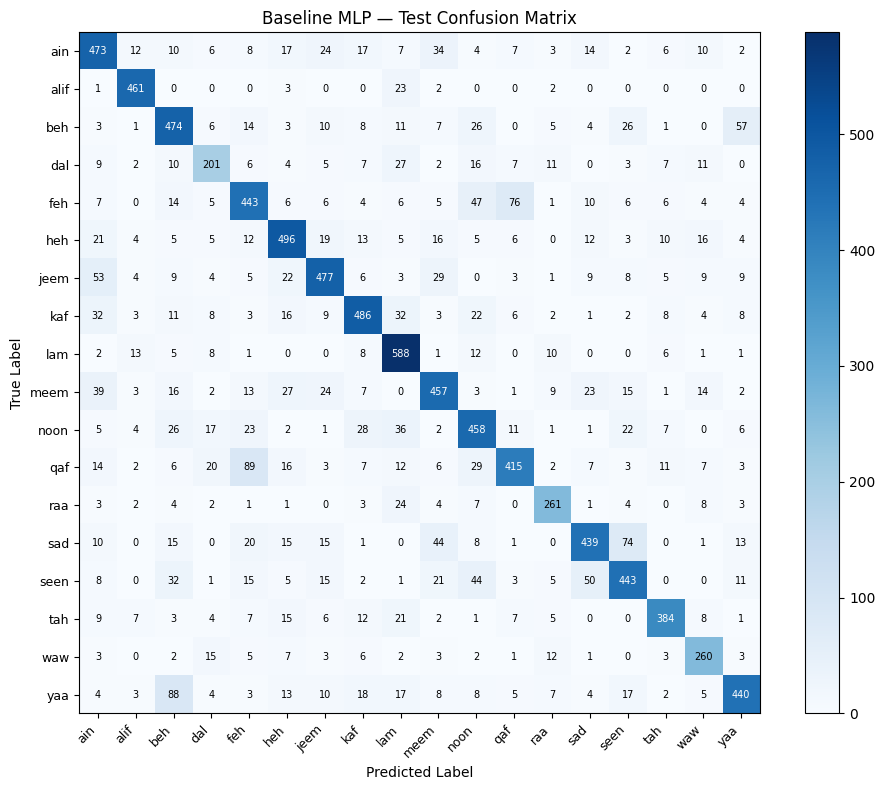

Saved confusion matrix to: /content/drive/MyDrive/DL_Project/results/baseline_mlp_confusion_matrix.png


In [ ]:
mlp_summary, y_pred_mlp, cm_mlp = evaluate_on_test(
    baseline_mlp, "Baseline MLP", "baseline_mlp"
)

================ Original Paper CNN ================
Train Accuracy:     96.29%
Val Accuracy:       93.89%
Test Accuracy:      93.61%
Weighted Precision: 93.69%
Weighted Recall:    93.61%
Weighted F1-Score:  93.61%
Macro Avg (P/R/F1): 93.44% / 93.40% / 93.37%

Per-Class Classification Report:
              precision    recall  f1-score   support

         ain     0.9133    0.8994    0.9063       656
        alif     0.9756    0.9756    0.9756       492
         beh     0.9120    0.9634    0.9370       656
         dal     0.8851    0.7988    0.8397       328
         feh     0.9223    0.9492    0.9356       650
         heh     0.8973    0.9248    0.9109       652
        jeem     0.9876    0.9710    0.9792       656
         kaf     0.9325    0.9482    0.9403       656
         lam     0.9217    0.9512    0.9362       656
        meem     0.8982    0.9284    0.9130       656
        noon     0.9645    0.9200    0.9417       650
         qaf     0.9617    0.8865    0.9226       652
   

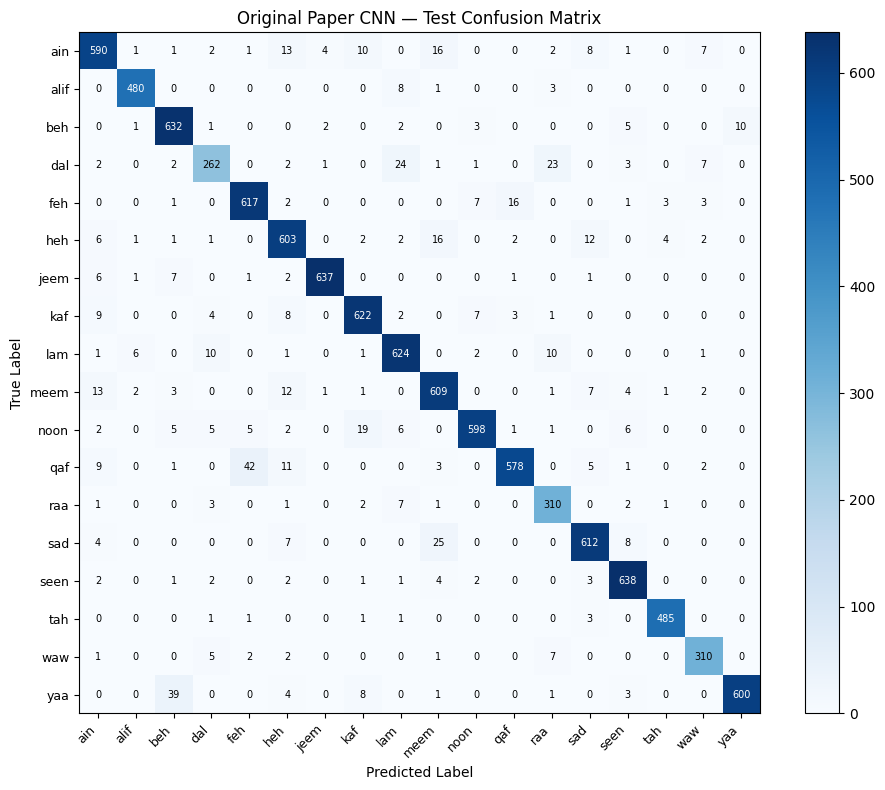

Saved confusion matrix to: /content/drive/MyDrive/DL_Project/results/paper_cnn_confusion_matrix.png


In [ ]:
cnn_summary, y_pred_cnn, cm_cnn = evaluate_on_test(
    paper_cnn, "Original Paper CNN", "paper_cnn"
)

In [ ]:
# Top 10 most confused letter pairs for the Paper CNN (helpful for Report Section 6 Discussion)
cm_errors = cm_cnn.copy()
np.fill_diagonal(cm_errors, 0)

pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm_errors[i, j] > 0:
            pairs.append({
                "True Letter": class_names[i],
                "Predicted As": class_names[j],
                "Mistakes": int(cm_errors[i, j]),
            })

top_confusions_df = pd.DataFrame(pairs).sort_values("Mistakes", ascending=False).head(10)
print("Top 10 Confused Letter Pairs (Original Paper CNN on Test Set):")
display(top_confusions_df)

Top 10 Confused Letter Pairs (Original Paper CNN on Test Set):


,True Letter,Predicted As,Mistakes
95,qaf,feh,42
133,yaa,beh,39
111,sad,meem,25
26,dal,lam,24
29,dal,raa,23
88,noon,kaf,19
35,feh,qaf,16
45,heh,meem,16
7,ain,meem,16
4,ain,heh,13


## 7. Combined Results Table & Comparison Plots


In [ ]:
paper_hijja_row = {
    "Model": "Paper CNN (Published)",
    "Dataset": "Hijja (29 classes)",
    "Train Acc (%)": 93.00,
    "Val Acc (%)": None,
    "Test Acc (%)": 88.00,
    "Precision (%)": 87.88,
    "Recall (%)": 87.81,
    "F1-Score (%)": 87.80,
    "Macro F1 (%)": 87.00,
}

paper_ahcd_row = {
    "Model": "Paper CNN (Published)",
    "Dataset": "AHCD (28 classes)",
    "Train Acc (%)": 98.00,
    "Val Acc (%)": None,
    "Test Acc (%)": 97.00,
    "Precision (%)": 96.78,
    "Recall (%)": 96.73,
    "F1-Score (%)": 96.73,
    "Macro F1 (%)": 97.00,
}

comparison_df = pd.DataFrame([
    paper_hijja_row,
    paper_ahcd_row,
    mlp_summary,
    cnn_summary,
])

display(comparison_df)

table_path = os.path.join(RESULTS_DIR, "final_comparison_table.csv")
comparison_df.to_csv(table_path, index=False)
print("Saved final comparison table to:", table_path)

,Model,Dataset,Train Acc (%),Val Acc (%),Test Acc (%),Precision (%),Recall (%),F1-Score (%),Macro F1 (%)
0,Paper CNN (Published),Hijja (29 classes),93.00,NaN,88.00,87.88,87.81,87.80,87.00
1,Paper CNN (Published),AHCD (28 classes),98.00,NaN,97.00,96.78,96.73,96.73,97.00
2,Baseline MLP,AHAWP (18 classes),91.77,72.66,73.08,73.28,73.08,73.00,73.32
3,Original Paper CNN,AHAWP (18 classes),96.29,93.89,93.61,93.69,93.61,93.61,93.37


Saved final comparison table to: /content/drive/MyDrive/DL_Project/results/final_comparison_table.csv


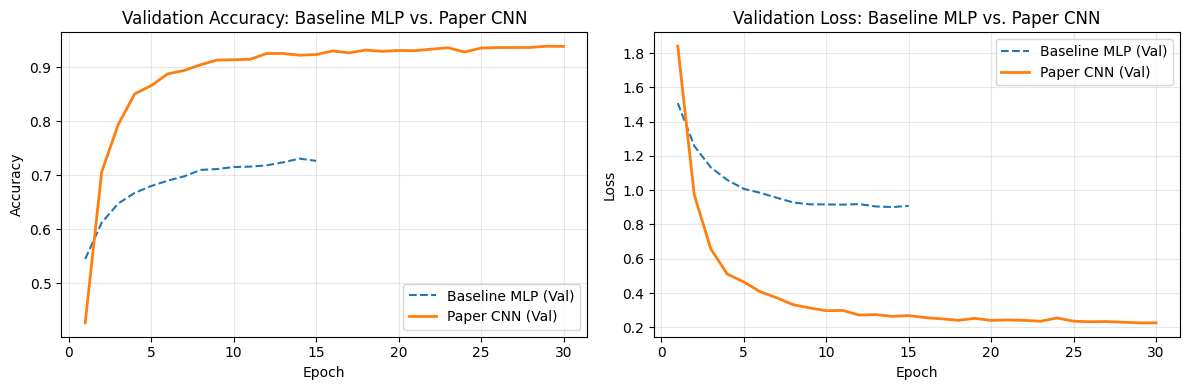

Saved comparison curves to: /content/drive/MyDrive/DL_Project/results/mlp_vs_paper_cnn_val_curves.png


In [ ]:
# Side-by-side Validation Curves: Baseline MLP vs. Original Paper CNN
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 15 + 1), mlp_history.history["val_accuracy"], label="Baseline MLP (Val)", linestyle="--")
axes[0].plot(epochs_range, cnn_history.history["val_accuracy"], label="Paper CNN (Val)", linewidth=2)
axes[0].set_title("Validation Accuracy: Baseline MLP vs. Paper CNN")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, 15 + 1), mlp_history.history["val_loss"], label="Baseline MLP (Val)", linestyle="--")
axes[1].plot(epochs_range, cnn_history.history["val_loss"], label="Paper CNN (Val)", linewidth=2)
axes[1].set_title("Validation Loss: Baseline MLP vs. Paper CNN")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

comp_plot_path = os.path.join(RESULTS_DIR, "mlp_vs_paper_cnn_val_curves.png")
plt.tight_layout()
plt.savefig(comp_plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved comparison curves to:", comp_plot_path)

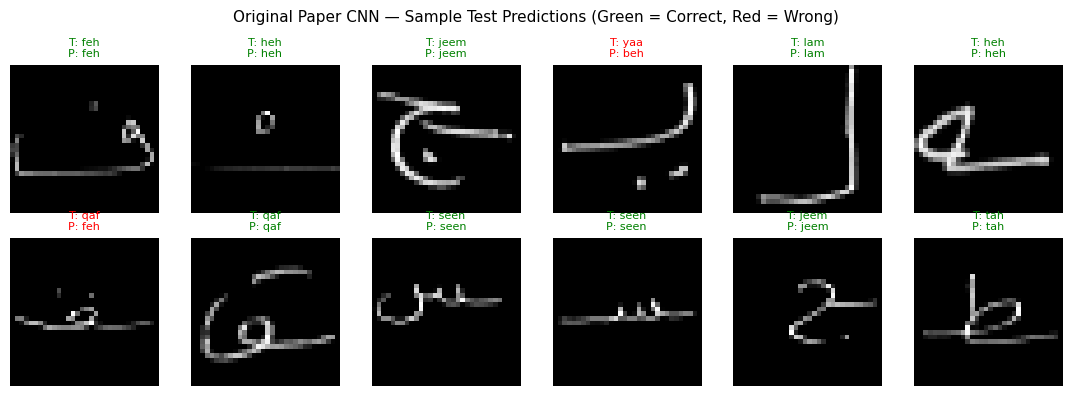

In [ ]:
# Visual check of 12 random test predictions from the Paper CNN
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X_test), size=12, replace=False)

plt.figure(figsize=(11, 4))
for i, idx in enumerate(sample_idx):
    t_lbl = class_names[y_test[idx]]
    p_lbl = class_names[y_pred_cnn[idx]]
    color = "green" if t_lbl == p_lbl else "red"

    plt.subplot(2, 6, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(f"T: {t_lbl}\nP: {p_lbl}", color=color, fontsize=8)
    plt.axis("off")

plt.suptitle("Original Paper CNN — Sample Test Predictions (Green = Correct, Red = Wrong)", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "paper_cnn_sample_predictions.png"), dpi=150, bbox_inches="tight")
plt.show()